In [1]:
import pandas as pd 
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, accuracy_score,r2_score,confusion_matrix

df = pd.read_excel("week10_students.xlsx")
df.to_csv("week10_students.csv",index= False)



In [3]:
import pandas as pd

df = pd.read_csv("week10_students.csv")
print("Shape:", df.shape)
print()
print(df[["quiz_avg", "assignments_avg", "attendance_pct"]].corrwith(df["score"]))

Shape: (150, 9)

quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

features = ["quiz_avg", "assignments_avg", "attendance_pct"]
X = df[features]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", len(X_train), "| Test:", len(X_test))

Train: 112 | Test: 38


In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

for name, coef in zip(features, model.coef_):
    print(f"{name}: {coef:.3f}")
print("Intercept:", round(model.intercept_, 3))

quiz_avg: 0.579
assignments_avg: 0.365
attendance_pct: 0.113
Intercept: -4.428


In [6]:
from sklearn.metrics import mean_absolute_error, r2_score

pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, pred), 2))
print("R2 :", round(r2_score(y_test, pred), 2))


MAE: 3.33
R2 : 0.89


In [7]:
new_student = pd.DataFrame({"quiz_avg": [70], "assignments_avg": [75], "attendance_pct": [90]})
print("New student predicted score:", round(model.predict(new_student)[0], 1))

# Me, with invented numbers
me = pd.DataFrame({"quiz_avg": [80], "assignments_avg": [85], "attendance_pct": [95]})
print("My predicted score:", round(model.predict(me)[0], 1))

New student predicted score: 73.7
My predicted score: 83.7


In [8]:
from sklearn.linear_model import LogisticRegression

df["passed"] = (df["score"] >= 50).astype(int)
print(df["passed"].value_counts())

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, df["passed"], test_size=0.25, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xc_train, yc_train)

passed
1    131
0     19
Name: count, dtype: int64


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix

pred_c = clf.predict(Xc_test)
print("Model accuracy :", round(accuracy_score(yc_test, pred_c), 3))
print("Lazy baseline  :", round(yc_test.mean(), 3))   # "everyone passes"
print("Confusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(yc_test, pred_c))

Model accuracy : 0.895
Lazy baseline  : 0.895
Confusion matrix (rows = actual, cols = predicted):
[[ 3  1]
 [ 3 31]]


In [10]:
# Is the model useless? NO.
# The two accuracies are close only because most students pass, so a lazy
# "everyone passes" model is already right most of the time. But the lazy model
# catches ZERO failing students (its whole fail row would be wrong).
# The confusion matrix [[3, 1], [3, 31]] shows our model correctly flags
# 3 of the 4 students who really failed, and it correctly passes 31 of 34 who
# passed. It makes 3 false alarms and misses 1 failing student. The lazy
# model flags 0 of 4. Both score 89.5%, but only ours is useful for finding
# at-risk students - accuracy alone hides that.

In [11]:
def test_r2(X_data):
    Xtr, Xte, ytr, yte = train_test_split(X_data, df["score"], test_size=0.25, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    return r2_score(yte, m.predict(Xte))

r2_quiz = test_r2(df[["quiz_avg"]])
r2_three = test_r2(df[features])
r2_prog = test_r2(pd.get_dummies(df[features + ["program"]], columns=["program"], dtype=int))

print("1. quiz_avg only        :", round(r2_quiz, 2))
print("2. three numeric        :", round(r2_three, 2))
print("3. three + program      :", round(r2_prog, 2))


1. quiz_avg only        : 0.62
2. three numeric        : 0.89
3. three + program      : 0.88


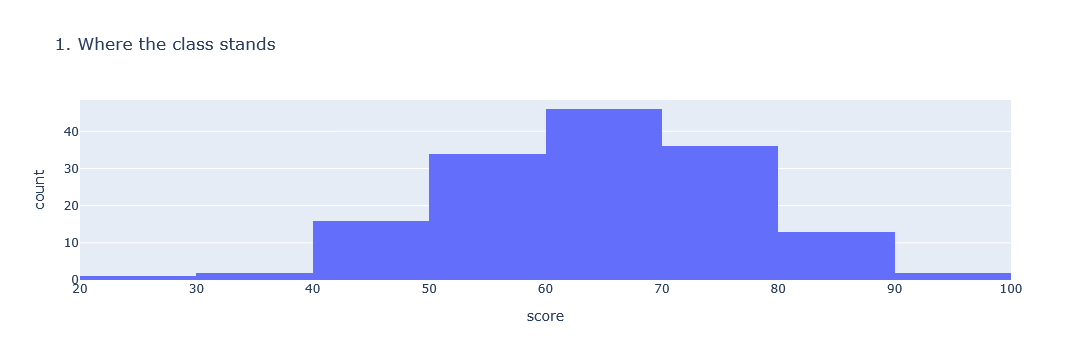

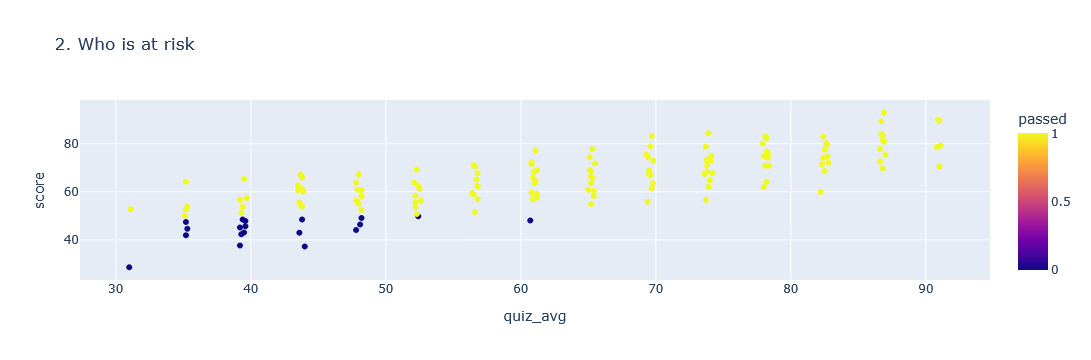

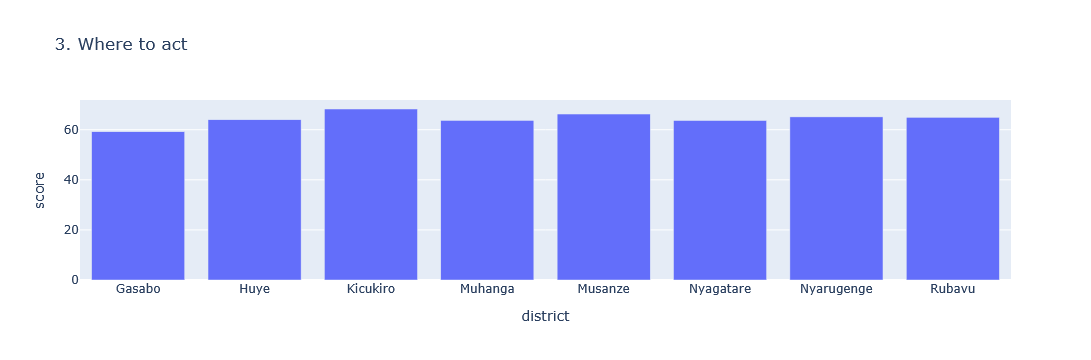

In [12]:
import plotly.express as px

fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()

fig2 = px.scatter(df, x="quiz_avg", y="score", color="passed", hover_name="name",
                  title="2. Who is at risk")
fig2.show()

district_avg = df.groupby("district", as_index=False)["score"].mean()
fig3 = px.bar(district_avg, x="district", y="score", title="3. Where to act")
fig3.show()

In [13]:
fig2.write_html("class_dashboard.html")
print("Saved class_dashboard.html - open it in your browser and take a screenshot.")

Saved class_dashboard.html - open it in your browser and take a screenshot.


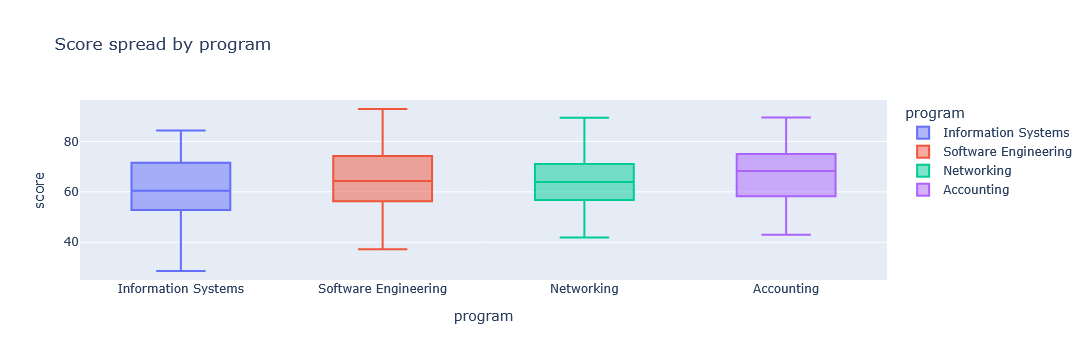

In [14]:
fig4 = px.box(df, x="program", y="score", color="program", title="Score spread by program")
fig4.show()

In [17]:
#Bonus answer:etworking is the most consistent program (smallest spread, std about 10.8). 
#Software Engineering has the widest spread (std about 13.8),
#with Information Systems close behind (scores from 28.6 to 84.4).

In [18]:
## Part 6 · Model Card

**1. Purpose** — Predicts a student's final score (0-100) from their quiz average, assignments average and attendance. It is for AUCA lecturers and advisors, to spot students who may need help early.

**2. Data & features** — 150 clean student records. Features: quiz_avg, assignments_avg, attendance_pct. Target: score. Name, gender, program and district were not used (adding program did not improve the model).

**3. Performance** — On 38 unseen students (25% hidden test set): MAE is about 3.3 points, so predictions are typically off by about 3 marks out of 100. R2 is about 0.89, so the model explains about 89% of the differences between students' scores.

**4. Risks** — A wrong prediction could label a capable student as 'at risk' (stigma, lowered expectations) or miss a struggling student who then gets no help. The model is trained on only 150 students and may not hold for other cohorts or courses. *Use it for:* an early-warning signal that prompts a conversation and extra support. *Do NOT use it for:* final grades, pass/fail decisions, discipline, scholarships or any decision made without a human reviewing the student's situation.